# ResNet1D for PTB-XL MI Detection

In [1]:
from __future__ import annotations

import json
import random
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import wfdb

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## Step 1: Paths and metadata loading

In [2]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    parent_candidate = PROJECT_ROOT.parent
    if (parent_candidate / "data").exists():
        PROJECT_ROOT = parent_candidate

LABELS_PATH = PROJECT_ROOT / "data" / "processed" / "ptbxl_labels.csv"
PTBXL_ROOT = PROJECT_ROOT / "data" / "raw" / "ptb-xl"

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
RESULTS_DIR = PROJECT_ROOT / "results" / "resnet1d"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 32
EPOCHS = 30
NUM_WORKERS = 0
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 7

FS = 500
N_LEADS = 12
N_SAMPLES = 5000

if not LABELS_PATH.is_file():
    raise FileNotFoundError(
        f"Label file not found: {LABELS_PATH}\n"
        "Edit LABELS_PATH above to point to your existing ptbxl_labels.csv."
    )

labels = pd.read_csv(LABELS_PATH)

if "ecg_id" not in labels.columns:
    unnamed = [c for c in labels.columns if str(c).startswith("Unnamed:")]
    if unnamed:
        labels = labels.rename(columns={unnamed[0]: "ecg_id"})
    else:
        raise ValueError(
            "Cannot find ecg_id in ptbxl_labels.csv. "
            f"Available columns: {labels.columns.tolist()}"
        )

labels["ecg_id"] = pd.to_numeric(labels["ecg_id"], errors="raise").astype(int)
labels = labels.set_index("ecg_id")

required_label_columns = {"patient_id", "mi_label", "dataset_split"}
missing = required_label_columns - set(labels.columns)
if missing:
    raise ValueError(
        f"Label CSV is missing columns: {sorted(missing)}. "
        f"Available columns: {labels.columns.tolist()}"
    )

if "filename_hr" not in labels.columns:
    metadata_candidates = [
        PTBXL_ROOT / "ptbxl_database.csv",
        PROJECT_ROOT / "data" / "ptb-xl" / "ptbxl_database.csv",
        PROJECT_ROOT / "data" / "raw" / "ptbxl_database.csv",
    ]
    metadata_path = next((p for p in metadata_candidates if p.is_file()), None)

    if metadata_path is None:
        raise FileNotFoundError(
            "Could not locate ptbxl_database.csv. Looked in:\n"
            + "\n".join(str(p) for p in metadata_candidates)
            + "\nSet PTBXL_ROOT to the directory containing ptbxl_database.csv."
        )

    metadata = pd.read_csv(metadata_path)
    if not {"ecg_id", "filename_hr"}.issubset(metadata.columns):
        raise ValueError(
            "ptbxl_database.csv must contain ecg_id and filename_hr. "
            f"Found: {metadata.columns.tolist()}"
        )

    metadata["ecg_id"] = pd.to_numeric(
        metadata["ecg_id"], errors="raise"
    ).astype(int)
    filename_lookup = metadata.set_index("ecg_id")["filename_hr"]
    labels["filename_hr"] = labels.index.to_series().map(filename_lookup)

    if labels["filename_hr"].isna().any():
        missing_ids = labels.index[labels["filename_hr"].isna()].tolist()[:10]
        raise ValueError(
            f"Could not find filename_hr for ecg_id values: {missing_ids}"
        )
    print("Restored filename_hr using:", metadata_path)

labels["mi_label"] = pd.to_numeric(
    labels["mi_label"], errors="raise"
).astype(int)

def select_split(split_name: str) -> pd.DataFrame:
    selected = labels[
        labels["dataset_split"].astype(str).str.lower() == split_name.lower()
    ].copy()
    if selected.empty:
        raise ValueError(
            f"No '{split_name}' split found. "
            f"Available: {labels['dataset_split'].unique().tolist()}"
        )
    return selected

train_df = select_split("train")
val_df = select_split("validation")
test_df = select_split("test")

patient_sets = [
    set(train_df["patient_id"]),
    set(val_df["patient_id"]),
    set(test_df["patient_id"]),
]
assert patient_sets[0].isdisjoint(patient_sets[1]), "Train/validation patient overlap"
assert patient_sets[0].isdisjoint(patient_sets[2]), "Train/test patient overlap"
assert patient_sets[1].isdisjoint(patient_sets[2]), "Validation/test patient overlap"

print("Train / validation / test records:",
      len(train_df), len(val_df), len(test_df))
print("Label columns:", labels.columns.tolist())
print("Example filename_hr:", train_df["filename_hr"].iloc[0])

Restored filename_hr using: c:\Users\sintu\Desktop\Myocardial Infarction\data\raw\ptb-xl\ptbxl_database.csv
Train / validation / test records: 17418 2183 2198
Label columns: ['patient_id', 'strat_fold', 'dataset_split', 'mi_label', 'mi_superclass_label', 'injury_label', 'mi_localization', 'number_of_localizations', 'loc_AMI', 'loc_IMI', 'loc_LMI', 'loc_PMI', 'filename_hr']
Example filename_hr: records500/00000/00001_hr


## Step 2: ECG loading and PyTorch Dataset

In [3]:
def resolve_record_path(filename: str) -> Path:
    relative_path = Path(filename)
    candidates = [
        PTBXL_ROOT / relative_path,
        PTBXL_ROOT / "records500" / relative_path,
        PROJECT_ROOT / "data" / "raw" / relative_path,
    ]
    for candidate in candidates:
        if candidate.with_suffix(".hea").is_file():
            return candidate
    raise FileNotFoundError(
        f"Could not locate WFDB header for {filename}. "
        f"Check PTBXL_ROOT: {PTBXL_ROOT}"
    )


class PTBXLMIDataset(Dataset):
    def __init__(self, frame: pd.DataFrame) -> None:
        self.frame = frame.copy()

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        row = self.frame.iloc[index]
        path = resolve_record_path(str(row["filename_hr"]))
        ecg, fields = wfdb.rdsamp(str(path))

        if int(fields["fs"]) != FS:
            raise ValueError(
                f"Expected {FS} Hz, received {fields['fs']} Hz: {path}"
            )
        if ecg.shape != (N_SAMPLES, N_LEADS):
            raise ValueError(
                f"Expected {(N_SAMPLES, N_LEADS)}, got {ecg.shape}: {path}"
            )

        signal_tensor = torch.tensor(ecg.T, dtype=torch.float32)
        target_tensor = torch.tensor(float(row["mi_label"]), dtype=torch.float32)
        return signal_tensor, target_tensor


train_loader = DataLoader(
    PTBXLMIDataset(train_df), batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    PTBXLMIDataset(val_df), batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
test_loader = DataLoader(
    PTBXLMIDataset(test_df), batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)

sample_x, sample_y = next(iter(train_loader))
assert sample_x.shape[1:] == (N_LEADS, N_SAMPLES)
print("Batch:", tuple(sample_x.shape), "Labels:", tuple(sample_y.shape))

Batch: (32, 12, 5000) Labels: (32,)


## Step 3: ResNet1D model

In [4]:
class ResidualBlock1D(nn.Module):
    def __init__(self, in_channels: int, out_channels: int,
                 stride: int = 1) -> None:
        super().__init__()
        self.conv1 = nn.Conv1d(
            in_channels, out_channels, kernel_size=7,
            stride=stride, padding=3, bias=False
        )
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.conv2 = nn.Conv1d(
            out_channels, out_channels, kernel_size=7,
            stride=1, padding=3, bias=False
        )
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm1d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)


class ResNet1D(nn.Module):
    def __init__(self, num_leads: int = 12, dropout: float = 0.25) -> None:
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv1d(num_leads, 64, kernel_size=15,
                      stride=2, padding=7, bias=False),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=3, stride=2, padding=1),
        )
        self.layer1 = nn.Sequential(
            ResidualBlock1D(64, 64),
            ResidualBlock1D(64, 64),
        )
        self.layer2 = nn.Sequential(
            ResidualBlock1D(64, 128, stride=2),
            ResidualBlock1D(128, 128),
        )
        self.layer3 = nn.Sequential(
            ResidualBlock1D(128, 256, stride=2),
            ResidualBlock1D(256, 256),
        )
        self.layer4 = nn.Sequential(
            ResidualBlock1D(256, 512, stride=2),
            ResidualBlock1D(512, 512),
        )
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(512, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        return self.classifier(self.pool(x)).squeeze(1)


model = ResNet1D(num_leads=N_LEADS).to(DEVICE)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
with torch.no_grad():
    print("Output shape:", model(sample_x.to(DEVICE)).shape)

Trainable parameters: 8737921
Output shape: torch.Size([32])


## Step 4: Training setup and helper functions

In [5]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)


def train_one_epoch() -> float:
    model.train()
    total_loss = 0.0
    total_samples = 0

    for signals, targets in train_loader:
        signals = signals.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(signals)
        loss = criterion(logits, targets)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * len(targets)
        total_samples += len(targets)

    return total_loss / total_samples


def get_predictions(loader: DataLoader):
    model.eval()
    probabilities = []
    targets_all = []
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for signals, targets in loader:
            signals = signals.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(signals)
            loss = criterion(logits, targets)
            probabilities.append(torch.sigmoid(logits).cpu().numpy())
            targets_all.append(targets.cpu().numpy())
            total_loss += loss.item() * len(targets)
            total_samples += len(targets)

    return (
        np.concatenate(probabilities),
        np.concatenate(targets_all).astype(int),
        total_loss / total_samples,
    )

## Step 5: Train with validation checkpointing and early stopping

In [6]:
history = []
best_validation_auc = -np.inf
best_epoch = 0
epochs_without_improvement = 0
checkpoint_path = CHECKPOINT_DIR / "resnet1d_mi_best.pt"

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch()
    val_prob, val_true, val_loss = get_predictions(val_loader)
    val_auc = roc_auc_score(val_true, val_prob)
    val_ap = average_precision_score(val_true, val_prob)
    scheduler.step(val_auc)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        "validation_roc_auc": val_auc,
        "validation_pr_auc": val_ap,
        "learning_rate": optimizer.param_groups[0]["lr"],
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
        f"val_ROC_AUC={val_auc:.4f} | val_PR_AUC={val_ap:.4f}"
    )

    if val_auc > best_validation_auc:
        best_validation_auc = val_auc
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "best_epoch": best_epoch,
                "best_validation_roc_auc": best_validation_auc,
            },
            checkpoint_path,
        )
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

history_df = pd.DataFrame(history)
display(history_df.tail())
print("Best validation ROC-AUC:", best_validation_auc)
print("Best epoch:", best_epoch)
print("Checkpoint:", checkpoint_path)

KeyboardInterrupt: 

## Step 6: Training curves

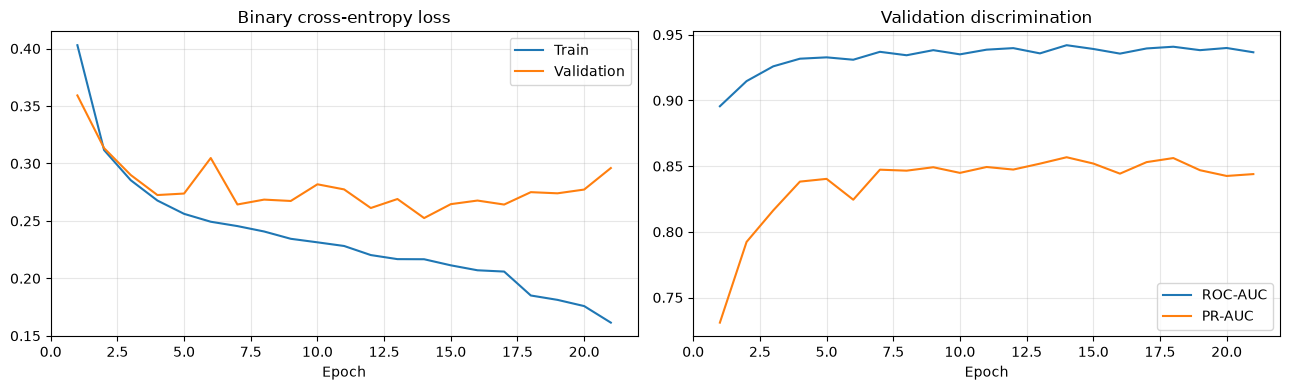

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
axes[0].plot(history_df["epoch"], history_df["validation_loss"], label="Validation")
axes[0].set_title("Binary cross-entropy loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_df["epoch"], history_df["validation_roc_auc"], label="ROC-AUC")
axes[1].plot(history_df["epoch"], history_df["validation_pr_auc"], label="PR-AUC")
axes[1].set_title("Validation discrimination")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 7: Select threshold on validation data and evaluate test data

In [ ]:
checkpoint = torch.load(
    checkpoint_path, map_location=DEVICE, weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])

val_prob, val_true, _ = get_predictions(val_loader)
threshold_grid = np.linspace(0.10, 0.90, 81)
threshold_rows = []

for threshold in threshold_grid:
    val_pred = (val_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": float(threshold),
        "f1": f1_score(val_true, val_pred, zero_division=0),
        "sensitivity": recall_score(val_true, val_pred, zero_division=0),
        "specificity": recall_score(
            val_true, val_pred, pos_label=0, zero_division=0
        ),
    })

threshold_df = pd.DataFrame(threshold_rows)
best_threshold = float(
    threshold_df.loc[threshold_df["f1"].idxmax(), "threshold"]
)
print("Validation-selected threshold:", best_threshold)
display(threshold_df.sort_values("f1", ascending=False).head(10))

test_prob, test_true, test_loss = get_predictions(test_loader)
test_pred = (test_prob >= best_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(
    test_true, test_pred, labels=[0, 1]
).ravel()

metrics: dict[str, Any] = {
    "threshold": best_threshold,
    "test_loss": float(test_loss),
    "accuracy": float(accuracy_score(test_true, test_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(test_true, test_pred)),
    "precision": float(precision_score(test_true, test_pred, zero_division=0)),
    "sensitivity_recall": float(recall_score(test_true, test_pred, zero_division=0)),
    "specificity": float(tn / (tn + fp)) if tn + fp else float("nan"),
    "f1": float(f1_score(test_true, test_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(test_true, test_prob)),
    "pr_auc_average_precision": float(
        average_precision_score(test_true, test_prob)
    ),
    "mcc": float(matthews_corrcoef(test_true, test_pred)),
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
}
display(pd.Series(metrics, name="test_value").to_frame())
print(classification_report(
    test_true, test_pred, target_names=["Non-MI", "MI"], zero_division=0
))

Validation-selected threshold: 0.38


,threshold,f1,sensitivity,specificity
28,0.38,0.760643,0.771593,0.919374
27,0.37,0.760113,0.775432,0.916968
29,0.39,0.757430,0.758157,0.923586
30,0.40,0.757225,0.754319,0.925391
26,0.36,0.757209,0.781190,0.911552
20,0.30,0.756614,0.823417,0.889290
21,0.31,0.755793,0.813820,0.893502
34,0.44,0.754527,0.719770,0.941035
23,0.33,0.754306,0.798464,0.900120
22,0.32,0.754275,0.804223,0.897112


,test_value
threshold,0.380000
test_loss,0.265414
accuracy,0.881711
balanced_accuracy,0.836885
precision,0.758555
sensitivity_recall,0.750000
specificity,0.923770
f1,0.754253
roc_auc,0.935358
pr_auc_average_precision,0.854584


              precision    recall  f1-score   support

      Non-MI       0.92      0.92      0.92      1666
          MI       0.76      0.75      0.75       532

    accuracy                           0.88      2198
   macro avg       0.84      0.84      0.84      2198
weighted avg       0.88      0.88      0.88      2198



## Step 8: Confusion matrix and ROC/PR curves

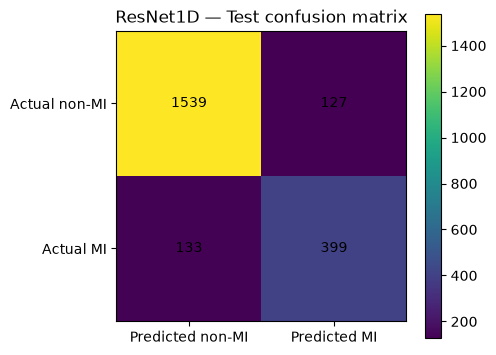

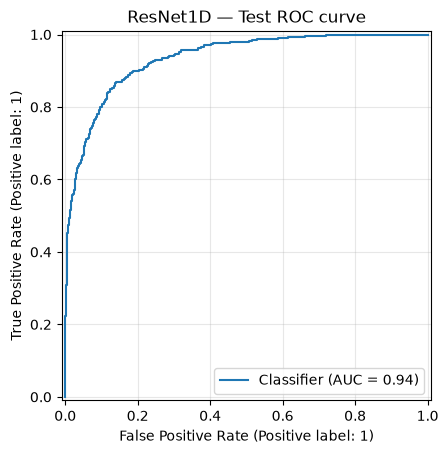

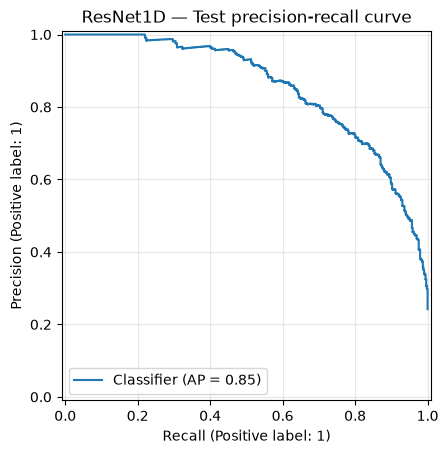

In [ ]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

cm = confusion_matrix(test_true, test_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm)
ax.set_xticks([0, 1], labels=["Predicted non-MI", "Predicted MI"])
ax.set_yticks([0, 1], labels=["Actual non-MI", "Actual MI"])
ax.set_title("ResNet1D — Test confusion matrix")
for (row, col), value in np.ndenumerate(cm):
    ax.text(col, row, str(value), ha="center", va="center")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(test_true, test_prob)
plt.title("ResNet1D — Test ROC curve")
plt.grid(alpha=0.3)
plt.show()

PrecisionRecallDisplay.from_predictions(test_true, test_prob)
plt.title("ResNet1D — Test precision-recall curve")
plt.grid(alpha=0.3)
plt.show()

## Step 9: Save experiment results

In [ ]:
history_df.to_csv(RESULTS_DIR / "training_history.csv", index=False)
threshold_df.to_csv(
    RESULTS_DIR / "validation_threshold_search.csv", index=False
)
with (RESULTS_DIR / "test_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)

metadata = {
    "model": "ResNet1D",
    "seed": SEED,
    "best_epoch": best_epoch,
    "best_validation_roc_auc": float(best_validation_auc),
    "threshold_selection": "maximum validation F1",
    "sampling_rate_hz": FS,
    "signal_shape_channels_first": [N_LEADS, N_SAMPLES],
    "train_records": len(train_df),
    "validation_records": len(val_df),
    "test_records": len(test_df),
    "patient_level_split_assertions_passed": True,
}
with (RESULTS_DIR / "experiment_metadata.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(metadata, file, indent=2)

print("Saved results to:", RESULTS_DIR)

Saved results to: c:\Users\sintu\Desktop\Myocardial Infarction\results\resnet1d
